# Chapitre 5 - Exercices 5.11 à 5.15

Noyau de la matrice de pénalité, poids et ex-æquo, validation croisée par augmentation
de l'échantillon, contraintes des splines de plaque mince, propriétés des RKHS.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch05_splines import SmoothingSpline, loocv_score
set_style()

## Exercice 5.11 : Noyau de la matrice de pénalité

**Énoncé.** Montrer que, pour une spline de lissage, le noyau de la matrice de pénalité
$\mathbf K$ (forme de Reinsch $\mathbf S_\lambda = (\mathbf I + \lambda\mathbf K)^{-1}$)
est engendré par les fonctions linéaires en $X$.

**Rappels.** Avec $x_1 < \dots < x_N$ distincts ($N \ge 2$), $\mathbf N$ la matrice
(inversible) de la base naturelle aux $x_i$ et $\mathbf K = \mathbf N^{-T}\Omega_N\mathbf
N^{-1}$ (exercice 5.9). Pour $\mathbf f \in \mathbb R^N$, soit $\theta = \mathbf
N^{-1}\mathbf f$ et $\hat f = \sum_j\theta_jN_j$ la spline naturelle interpolant les
valeurs $\mathbf f$ aux $x_i$. Alors

$$
\mathbf f^T\mathbf K\mathbf f = \theta^T\Omega_N\theta = \int\hat f''(t)^2\,dt .
$$

**Solution.** $\mathbf K$ est symétrique semi-définie positive. Pour une telle matrice,
$\mathbf K\mathbf f = 0 \iff \mathbf f^T\mathbf K\mathbf f = 0$. En effet, en diagonalisant
$\mathbf K = \sum_kd_k\mathbf u_k\mathbf u_k^T$ ($d_k \ge 0$),
$\mathbf f^T\mathbf K\mathbf f = \sum_kd_k\langle\mathbf u_k, \mathbf f\rangle^2$ est nul
ssi $\langle\mathbf u_k, \mathbf f\rangle = 0$ pour tout $k$ tel que $d_k > 0$, ssi
$\mathbf K\mathbf f = \sum_kd_k\langle\mathbf u_k, \mathbf f\rangle\mathbf u_k = 0$.

Or $\int\hat f''^2 = 0 \iff \hat f'' \equiv 0$ (fonction continue, positive, d'intégrale
nulle) $\iff \hat f$ affine $\iff f_i = a + bx_i$ pour tout $i$ (si les $f_i$ sont alignés,
la droite est une spline naturelle qui les interpole, et c'est la seule par unicité).
Donc

$$
\ker\mathbf K = \{(a + bx_i)_{i=1..N} : a, b \in \mathbb R\} = \mathrm{Vect}(\mathbf 1, \mathbf x),
$$

de dimension 2. Conséquence : $\mathbf S_\lambda\mathbf f = \mathbf f$ pour $\mathbf f$
affine, quel que soit $\lambda$ (les deux valeurs propres $\rho_k = 1$ du cours 2).

**Vérification numérique** : on reconstitue $\mathbf K = (\mathbf S_\lambda^{-1} -
\mathbf I)/\lambda$ et l'on examine ses plus petites valeurs propres et les vecteurs propres
associés.

In [2]:
rng = np.random.RandomState(0)
n = 50
x = np.sort(rng.uniform(0, 1, n))
lam = 1e-3
S = SmoothingSpline(lam=lam).fit(x, np.zeros(n)).smoother_matrix()
K = (np.linalg.inv(S) - np.eye(n)) / lam
K = (K + K.T) / 2
d, U = np.linalg.eigh(K)
print("3 plus petites valeurs propres de K :", np.round(d[:3], 6) + 0.0)
P = np.column_stack([np.ones(n), x])
proj = P @ np.linalg.lstsq(P, U[:, :2], rcond=None)[0]
print("résidu de projection des 2 premiers vecteurs propres sur Vect(1, x) :", np.abs(proj - U[:, :2]).max())
v = 2 - 3 * x
print("||K v|| / (||K|| ||v||) pour v = 2 - 3x :", np.linalg.norm(K @ v) / (np.linalg.norm(K, 2) * np.linalg.norm(v)))

3 plus petites valeurs propres de K : [0.       0.       9.301486]
résidu de projection des 2 premiers vecteurs propres sur Vect(1, x) : 3.015522886951061e-09
||K v|| / (||K|| ||v||) pour v = 2 - 3x : 7.367887060510247e-15


> **À retenir.** $\mathbf f^T\mathbf K\mathbf f$ est la courbure de l'interpolant
> naturel ; elle s'annule exactement pour les vecteurs alignés : le noyau de $\mathbf K$
> est $\mathrm{Vect}(\mathbf 1, \mathbf x)$, et ces composantes ne sont jamais rétrécies.

## Exercice 5.12 : Poids et observations ex æquo

**Énoncé.** Caractériser la solution de (éq. (5.73))

$$
\min_f\ \sum_{i=1}^{N}w_i\{y_i - f(x_i)\}^2 + \lambda\int\{f''(t)\}^2dt,\qquad w_i \ge 0 .
$$

Caractériser ensuite la solution de (5.9) lorsque les $x_i$ présentent des ex æquo.

**Poids.** L'argument de l'exercice 5.7 s'applique tel quel : remplacer $f$ par la spline
naturelle $g$ interpolant les valeurs $f(x_i)$ ne change pas le premier terme (pondéré ou
non) et ne peut que diminuer la pénalité. La solution est donc une **spline cubique
naturelle à nœuds aux valeurs distinctes des $x_i$** (celles de poids nul peuvent être
omises). Dans la base naturelle, avec $\mathbf W = \mathrm{diag}(w_i)$ :

$$
(\mathbf y - \mathbf N\theta)^T\mathbf W(\mathbf y - \mathbf N\theta) + \lambda\theta^T\Omega_N\theta
\quad\Longrightarrow\quad
\hat\theta = (\mathbf N^T\mathbf W\mathbf N + \lambda\Omega_N)^{-1}\mathbf N^T\mathbf W\mathbf y,
$$

et $\hat{\mathbf f} = \mathbf S_{\lambda,w}\mathbf y$ avec
$\mathbf S_{\lambda,w} = \mathbf N(\mathbf N^T\mathbf W\mathbf N + \lambda\Omega_N)^{-1}
\mathbf N^T\mathbf W$ (non symétrique en général). Quand $\mathbf N$ est carrée inversible
et $\mathbf W$ inversible : $\mathbf S_{\lambda,w} = (\mathbf I + \lambda\mathbf W^{-1}\mathbf K)^{-1}$.
C'est ce lisseur pondéré qui intervient dans la régression logistique non paramétrique
(éq. (5.33)-(5.34)).

**Ex æquo.** Supposons que les $x_i$ prennent $n < N$ valeurs distinctes $u_1, \dots,
u_n$, la valeur $u_j$ étant prise $n_j$ fois, avec moyenne des réponses
$\bar y_j = \frac1{n_j}\sum_{i : x_i = u_j}y_i$. Pour tout $f$, en développant
$y_i - f(u_j) = (y_i - \bar y_j) + (\bar y_j - f(u_j))$ et en remarquant que
$\sum_{i : x_i = u_j}(y_i - \bar y_j) = 0$ (le double produit disparaît) :

$$
\sum_{i=1}^{N}\{y_i - f(x_i)\}^2 = \sum_{j=1}^{n}n_j\{\bar y_j - f(u_j)\}^2
  + \underbrace{\sum_{j}\sum_{i : x_i = u_j}(y_i - \bar y_j)^2}_{\text{indépendant de } f}.
$$

Le problème (5.9) avec ex æquo équivaut donc à une **spline de lissage pondérée** sur les
$n$ points $(u_j, \bar y_j)$ avec poids $w_j = n_j$ : spline naturelle à $n$ nœuds, de
matrice de lissage $n \times n$.

**Vérification** sur les données *bone* (filles), qui comportent de nombreux ex æquo.

In [3]:
bone = datasets.load_bone()
fem = bone[bone["gender"] == "female"]
xa, ya = fem["age"].to_numpy(), fem["spnbmd"].to_numpy()
agr = fem.groupby("age")["spnbmd"].agg(["mean", "size"]).reset_index()
print("N = %d observations, n = %d âges distincts" % (len(xa), len(agr)))
lam = 1.0
s_full = SmoothingSpline(lam=lam).fit(xa, ya)
s_agr = SmoothingSpline(lam=lam).fit(agr["age"].to_numpy(), agr["mean"].to_numpy(),
                                     w=agr["size"].to_numpy(float))
grille = np.linspace(xa.min(), xa.max(), 300)
print("écart max entre les deux ajustements :", np.abs(s_full.predict(grille) - s_agr.predict(grille)).max())
print("ddl : %.4f (données complètes) vs %.4f (moyennes pondérées)" % (s_full.df_, s_agr.df_))

N = 259 observations, n = 168 âges distincts
écart max entre les deux ajustements : 3.427952366408249e-13
ddl : 12.1463 (données complètes) vs 12.1463 (moyennes pondérées)


**Effet des poids.** Donnons un poids 20 fois plus fort aux observations d'âge supérieur à
20 ans : la courbe s'en rapproche (comportement d'un ajustement pondéré).

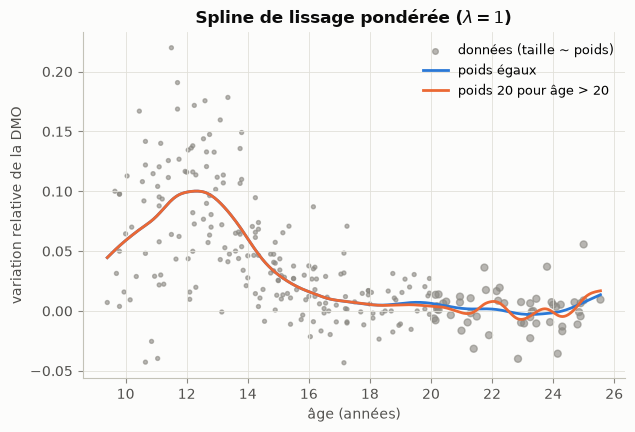

In [4]:
w = np.where(xa > 20, 20.0, 1.0)
s_w = SmoothingSpline(lam=lam).fit(xa, ya, w=w)
plt.figure(figsize=(7, 4.5))
plt.scatter(xa, ya, s=np.where(xa > 20, 25, 8), color=GRAY, alpha=0.6, label="données (taille ~ poids)")
plt.plot(grille, s_full.predict(grille), color=BLUE, label="poids égaux")
plt.plot(grille, s_w.predict(grille), color=ORANGE, label="poids 20 pour âge > 20")
plt.xlabel("âge (années)")
plt.ylabel("variation relative de la DMO")
plt.title("Spline de lissage pondérée ($\\lambda = 1$)")
plt.legend()
plt.show()

> **À retenir.** Avec des poids, la solution reste une spline naturelle à nœuds aux $x_i$
> distincts, obtenue par ridge généralisée pondérée. Des ex æquo se traitent en remplaçant
> chaque groupe par sa moyenne, pondérée par l'effectif.

## Exercice 5.13 : Augmenter l'échantillon par un point ajusté ; formule de la CV

**Énoncé.** On a ajusté une spline de lissage $\hat f_\lambda$ à $N$ couples $(x_i, y_i)$.
On ajoute le couple $(x_0, \hat f_\lambda(x_0))$ et l'on réajuste (même $\lambda$).
Décrire le résultat, et en déduire la formule (5.26)-(5.27) de la validation croisée
« leave-one-out ».

**Le résultat ne change pas.** Notons $R_N(f) = \sum_{i=1}^{N}(y_i - f(x_i))^2 +
\lambda\int f''^2$ et $R_{N+1}(f) = R_N(f) + (\hat f_\lambda(x_0) - f(x_0))^2$ le critère
augmenté. Pour toute $f$ :

$$
R_{N+1}(f) \;\ge\; R_N(f) \;\ge\; R_N(\hat f_\lambda) \;=\; R_{N+1}(\hat f_\lambda),
$$

(le terme ajouté est $\ge 0$ ; $\hat f_\lambda$ minimise $R_N$ ; le terme ajouté est nul
en $\hat f_\lambda$). Donc $\hat f_\lambda$ minimise aussi $R_{N+1}$, et par unicité du
minimiseur, le réajustement redonne **exactement** $\hat f_\lambda$.

**Formule de la CV.** Soit $\hat f^{(-i)}$ la spline ajustée sans l'observation $i$.
D'après ce qui précède, ajouter le point $(x_i, \hat f^{(-i)}(x_i))$ à l'échantillon privé
de $i$ redonne $\hat f^{(-i)}$. Mais cet échantillon augmenté est l'échantillon complet où
$y_i$ est remplacé par $y_i^* = \hat f^{(-i)}(x_i)$ : mêmes $x$, même $\lambda$, donc même
matrice de lissage $\mathbf S_\lambda$. En notant $\mathbf y^*$ ce vecteur :

$$
\hat f^{(-i)}(x_i) = \sum_{j \ne i}S_{ij}y_j + S_{ii}\hat f^{(-i)}(x_i),\qquad
\hat f_\lambda(x_i) = \sum_{j \ne i}S_{ij}y_j + S_{ii}y_i .
$$

En soustrayant : $\hat f^{(-i)}(x_i) - \hat f_\lambda(x_i) = S_{ii}(\hat f^{(-i)}(x_i) -
y_i)$. Posons $r_i = y_i - \hat f^{(-i)}(x_i)$ ; alors
$y_i - \hat f_\lambda(x_i) = r_i + (\hat f^{(-i)}(x_i) - \hat f_\lambda(x_i)) = r_i -
S_{ii}r_i$, d'où

$$
y_i - \hat f^{(-i)}(x_i) = \frac{y_i - \hat f_\lambda(x_i)}{1 - S_{ii}},\qquad
\mathrm{CV}(\hat f_\lambda) = \frac1N\sum_{i=1}^{N}\left(\frac{y_i - \hat
f_\lambda(x_i)}{1 - S_\lambda(i,i)}\right)^2 .
$$

**Vérifications numériques.** D'abord l'invariance par ajout d'un point ajusté, puis la
formule des résidus « leave-one-out », observation par observation.

In [5]:
rng = np.random.RandomState(3)
n = 60
x = np.sort(rng.uniform(0, 1, n))
fsim = lambda t: np.sin(12 * (t + 0.2)) / (t + 0.2)
y = fsim(x) + rng.randn(n)
lam = 1e-5
s = SmoothingSpline(lam=lam).fit(x, y)
x0 = 0.4321
s_aug = SmoothingSpline(lam=lam).fit(np.r_[x, x0], np.r_[y, s.predict(np.array([x0]))])
g = np.linspace(0, 1, 500)
print("écart max entre ajustement initial et augmenté :", np.abs(s.predict(g) - s_aug.predict(g)).max())

écart max entre ajustement initial et augmenté : 4.1966430330830917e-13


In [6]:
Sm = s.smoother_matrix()
r_formule = (y - Sm @ y) / (1 - np.diag(Sm))
r_direct = np.array([y[i] - SmoothingSpline(lam=lam).fit(np.delete(x, i), np.delete(y, i))
                     .predict(x[i:i + 1])[0] for i in range(n)])
print("écart max entre résidus LOO directs et formule :", np.abs(r_formule - r_direct).max())
print("CV = %.5f (formule) = %.5f (direct)" % (np.mean(r_formule ** 2), np.mean(r_direct ** 2)))

écart max entre résidus LOO directs et formule : 4.425348976155874e-13
CV = 1.30197 (formule) = 1.30197 (direct)


In [ ]:
plt.figure(figsize=(7, 4.5))
plt.scatter(r_direct, r_formule, s=15, color=BLUE)
lim = np.abs(r_direct).max() * 1.1
plt.plot([-lim, lim], [-lim, lim], color=GRAY, lw=1, ls="--", label="première bissectrice")
plt.xlabel(r"$y_i - \hat f^{(-i)}(x_i)$ (réajustement)")
plt.ylabel(r"$(y_i - \hat f(x_i))/(1 - S_{ii})$")
plt.title("Résidus de validation croisée : formule (5.27)")
plt.legend()
plt.show()

> **À retenir.** Ajouter un point situé sur la courbe ajustée ne change rien. Cette
> remarque, combinée à la linéarité du lisseur, donne les résidus « leave-one-out » sans
> aucun réajustement : $r_i = (y_i - \hat f_i)/(1 - S_{ii})$. La même formule vaut pour
> tout lisseur linéaire ayant cette propriété (moindres carrés, ridge, ridge à noyau…).

## Exercice 5.14 : Splines de plaque mince : finitude de la pénalité

**Énoncé.** Pour le développement (5.39)
$f(x) = \beta_0 + \beta^Tx + \sum_{j=1}^{N}\alpha_jh_j(x)$, avec
$h_j(x) = \eta(\|x - x_j\|)$, $\eta(r) = r^2\log r$, $x \in \mathbb R^2$, établir les
contraintes sur les $\alpha_j$ garantissant que la pénalité $J(f)$ (5.38) est finie.
Comment assurer autrement la finitude de la pénalité ?

**Rappels.** $J(f) = \iint_{\mathbb R^2}\|\nabla^2 f(x)\|_F^2\,dx$, où $\nabla^2f$ est la
matrice hessienne et $\|\mathbf A\|_F^2 = \sum_{k,l}A_{kl}^2 = f_{11}^2 + 2f_{12}^2 +
f_{22}^2$. La partie affine $\beta_0 + \beta^Tx$ a une hessienne nulle.

**Hessienne de $g(x) = \|x\|^2\log\|x\|$.** Avec $r = \|x\|$ : $\nabla g = x\,(2\log r +
1)$ (car $\nabla r = x/r$), puis

$$
\nabla^2g(x) = (2\log r + 1)\,\mathbf I + 2\,\frac{xx^T}{r^2} =: \mathbf M(x).
$$

Ses coefficients croissent comme $\log r$ : $\iint\|\mathbf M\|_F^2$ diverge (comme
$\int^{\infty}(\log r)^2\,r\,dr$). Près de $x = 0$, la singularité en $\log r$ est de carré
intégrable : seul le comportement à l'infini pose problème.